# Lab-work #1

First name     - Olha

Second name    - Moskovska

Group          - CS-42

In [20]:
%pip install ultralytics

  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.4 MB 4.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 7.1 MB/s  0:00:00
   ---------------------------------------- 0.0/876.6 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/876.6 kB ? eta -:--:--
   ---------------------------------------- 876.6/876.6 kB 2.9 MB/s  0:00:00
   ---------------------------------------- 0.0/54.2 MB ? eta -:--:--
   - -------------------------------------- 1.8/54.2 MB 10.4 MB/s eta 0:00:06
   -- ------------------------------------- 2.9/54.2 MB 10.5 MB/s eta 0:00:05
   ---- ----------------------------------- 5.5/54.2 MB 9.4 MB/s eta 0:00:06
   ----- ---------------------------------- 7.6/54.2 MB 10.0 MB/s eta 0:00:05
   ----- ---------------------------------- 7.9/54.2 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [12]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['image.interpolation'] = 'nearest'


### Dataset Configuration & Image Loading

In [13]:
DATA_DIR = os.path.join("aquarium", "test", "images")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join("lab_works_2026_2027_1st_sem", "lab_1", "src", "human_ROI_test")

image_extensions = ("*.jpg", "*.jpeg", "*.png")

image_paths = []
for ext in image_extensions:
    image_paths.extend(glob.glob(os.path.join(DATA_DIR, ext)))
image_paths = sorted(image_paths)

print(f"Found {len(image_paths)} images in '{DATA_DIR}':")
for p in image_paths[:5]:
    print(f" - {os.path.basename(p)}")


def load_image(image_path: str) -> np.ndarray:
    """Load an image from disk and convert BGR (OpenCV default) to RGB."""
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Image not found at path: {image_path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)



Found 63 images in 'aquarium\test\images':
 - IMG_2289_jpeg_jpg.rf.fe2a7a149e7b11f2313f5a7b30386e85.jpg
 - IMG_2301_jpeg_jpg.rf.2c19ae5efbd1f8611b5578125f001695.jpg
 - IMG_2319_jpeg_jpg.rf.6e20bf97d17b74a8948aa48776c40454.jpg
 - IMG_2347_jpeg_jpg.rf.7c71ac4b9301eb358cd4a832844dedcb.jpg
 - IMG_2354_jpeg_jpg.rf.396e872c7fb0a95e911806986995ee7a.jpg


### Grounding DINO Zero-Shot Object Detection

In [14]:

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "IDEA-Research/grounding-dino-tiny"

print(f"Loading Grounding DINO on {DEVICE}...")
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForZeroShotObjectDetection.from_pretrained(MODEL_ID).to(DEVICE)


def detect_objects_dino(
    image_rgb: np.ndarray,
    text_prompt: str = "fish. penguin. puffin. shark. stingray. bird.",
    box_threshold: float = 0.25,
    text_threshold: float = 0.25
) -> tuple:
    """
    Performs zero-shot object detection using Grounding DINO.
    Returns:
        boxes: List of bounding boxes [(x, y, w, h), ...]
        labels: List of detected class labels
        scores: List of confidence scores
    """
    pil_img = Image.fromarray(image_rgb)
    inputs = processor(images=pil_img, text=text_prompt, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)

    results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=box_threshold,        
    text_threshold=text_threshold,
    target_sizes=[image_rgb.shape[:2]]
    )[0]

    boxes_xywh = []
    labels = results["labels"]
    scores = results["scores"].cpu().numpy()

    for box in results["boxes"].cpu().numpy():
        xmin, ymin, xmax, ymax = box.astype(int)
        x = max(0, xmin)
        y = max(0, ymin)
        w = max(0, xmax - xmin)
        h = max(0, ymax - ymin)
        boxes_xywh.append((x, y, w, h))

    return boxes_xywh, labels, scores



Loading Grounding DINO on cpu...


Loading weights: 100%|██████████| 978/978 [00:00<00:00, 1177.79it/s]


### Segmentation via GrabCut (using DINO's accurate ROI)

In [15]:

def segment_roi_grabcut(image_rgb: np.ndarray, bbox: tuple, iterations: int = 5) -> tuple:
    x, y, w, h = bbox
    img_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)

    mask = np.zeros(img_bgr.shape[:2], np.uint8)
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        img_bgr,
        mask,
        (x, y, w, h),
        bgd_model,
        fgd_model,
        iterations,
        cv2.GC_INIT_WITH_RECT
    )

    binary_mask = np.where((mask == 1) | (mask == 3), 1, 0).astype("uint8")
    segmented_rgb = image_rgb * binary_mask[:, :, np.newaxis]
    return binary_mask, segmented_rgb


def track_across_sequence(image_paths: list, initial_bbox: tuple):

    tracker = cv2.TrackerCSRT_create() if hasattr(cv2, 'TrackerCSRT_create') else cv2.TrackerKCF_create()

    first_frame_bgr = cv2.imread(image_paths[0])
    tracker.init(first_frame_bgr, initial_bbox)

    tracked_results = []

    for path in image_paths:
        frame_bgr = cv2.imread(path)
        if frame_bgr is None:
            continue

        success, box = tracker.update(frame_bgr)
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

        if success:
            x, y, w, h = [int(v) for v in box]
            cv2.rectangle(frame_rgb, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.putText(
                frame_rgb, "Tracking", (x, max(20, y - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
            )
        else:
            cv2.putText(
                frame_rgb, "Lost Target", (30, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2
            )

        tracked_results.append(frame_rgb)

    return tracked_results




###  Pipeline Execution & Visualization

Detected 3 object(s): ['aquatic bird', 'puffin', 'fish']


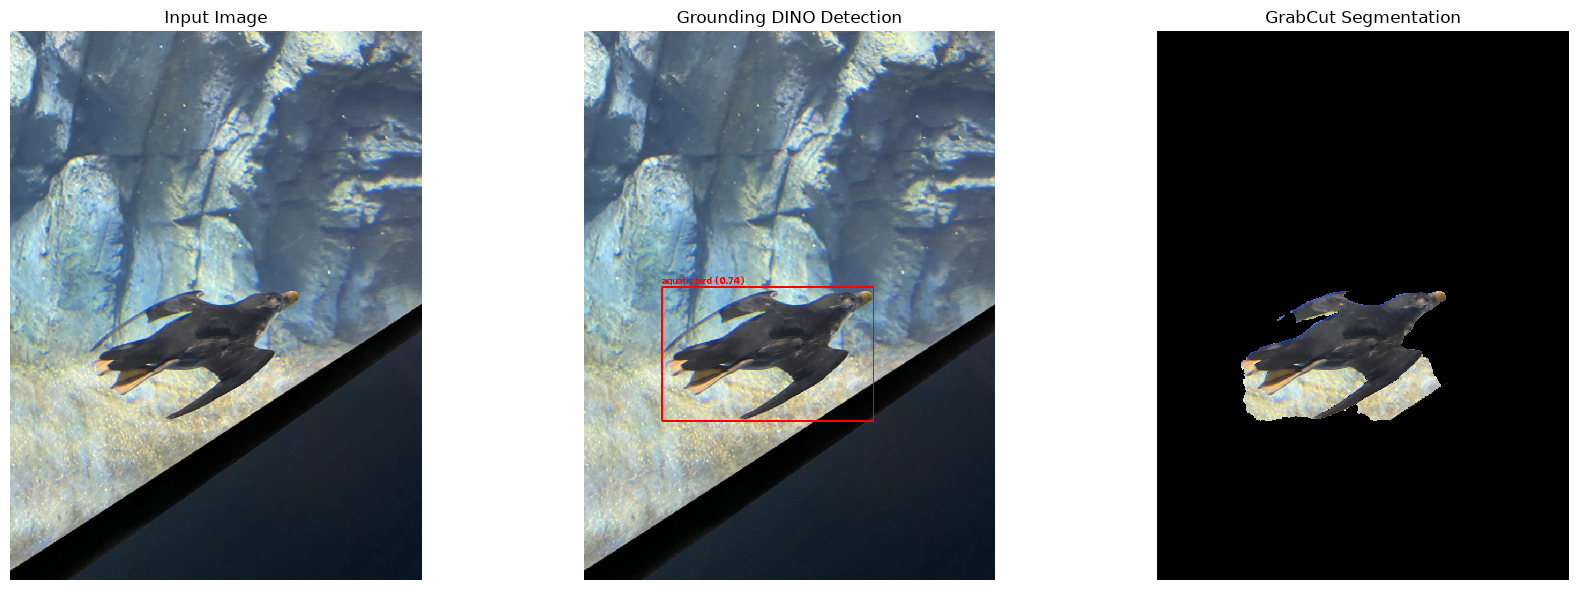

Tracked target across 5 sequential images.


In [16]:

if len(image_paths) > 0:
    sample_img = load_image(image_paths[0])

    # 1. Zero-Shot Detection using DINO
    # Prompts for Grounding DINO must end with periods: "item1. item2."
    prompt = "penguin. puffin. aquatic bird. fish."
    boxes, labels, scores = detect_objects_haar_dino = detect_objects_dino(
        sample_img,
        text_prompt=prompt,
        box_threshold=0.25,
        text_threshold=0.25
    )

    print(f"Detected {len(boxes)} object(s): {labels}")

    if len(boxes) > 0:
        target_box = boxes[0]
        target_label = f"{labels[0]} ({scores[0]:.2f})"

        # 2. Out-of-the-box Segmentation using the DINO-detected bounding box
        mask, segmented_fg = segment_roi_grabcut(sample_img, target_box)

        # 3. Visualization
        det_img = sample_img.copy()
        x, y, w, h = target_box
        cv2.rectangle(det_img, (x, y), (x + w, y + h), (255, 0, 0), 2)
        cv2.putText(
            det_img, target_label, (x, max(20, y - 6)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2
        )

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        axes[0].imshow(sample_img)
        axes[0].set_title("Input Image")
        axes[0].axis("off")

        axes[1].imshow(det_img)
        axes[1].set_title("Grounding DINO Detection")
        axes[1].axis("off")

        axes[2].imshow(segmented_fg)
        axes[2].set_title("GrabCut Segmentation")
        axes[2].axis("off")

        plt.tight_layout()
        plt.show()

        # 4. Tracking across image sequence
        if len(image_paths) > 1:
            tracked_sequence = track_across_sequence(image_paths[:5], target_box)
            print(f"Tracked target across {len(tracked_sequence)} sequential images.")
    else:
        print("No objects matched the text prompt. Try lowering 'box_threshold' or adding classes to 'prompt'.")

Grounding DINO successfully localized the aquatic bird with a tight bounding box, enabling GrabCut to isolate the subject from the surrounding background. However, the segmentation retains some adjacent rock texture beneath the bird where color contrast is low, illustrating that while language-grounded zero-shot detection robustly identifies domain-specific objects, classical color-distribution-based segmentation benefits from additional refinement or learned instance-segmentation masks.

## YOLO nano fine-tuning

### Configurations

In [23]:
import os
import time
import glob
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

import yaml

_src = Path("aquarium").resolve()
if not (_src / "data.yaml").exists():
    _src = Path.cwd() / "aquarium"
_cfg = yaml.safe_load((_src / "data.yaml").read_text())
_cfg.update(path=_src.as_posix(), train="train/images", val="valid/images", test="test/images")
DATA_YAML = str(_src / "data_abs.yaml")
Path(DATA_YAML).write_text(yaml.safe_dump(_cfg))
DEVICE = 0 if torch.cuda.is_available() else "cpu"
EPOCHS = 30
BATCH_SIZE = 16
IMG_SZ = 640

### Benchmark Pre-trained Baseline Model

--- Benchmarking Pre-trained Baseline ---
Ultralytics 8.4.178  Python-3.14.7 torch-2.14.1+cpu CPU (11th Gen Intel Core i7-11370H @ 3.30GHz)
YOLOv10n summary (fused): 99 layers, 2,299,264 parameters, 0 gradients, 6.8 GFLOPs
WARNING val: Slow image access detected (ping: 0.5±0.6 ms, read: 49.6±63.3 MB/s, size: 125.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\CS42\ML\Lab1\aquarium\test\labels... 63 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63 424.9it/s 0.1s0.2s
val: New cache created: D:\CS42\ML\Lab1\aquarium\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0it/s 3.9s1.5ss
                   all         63        584     0.0319      0.137      0.034     0.0244
                person         30        249     0.0531      0.261     0.0148    0.00706
               bicycle         11 

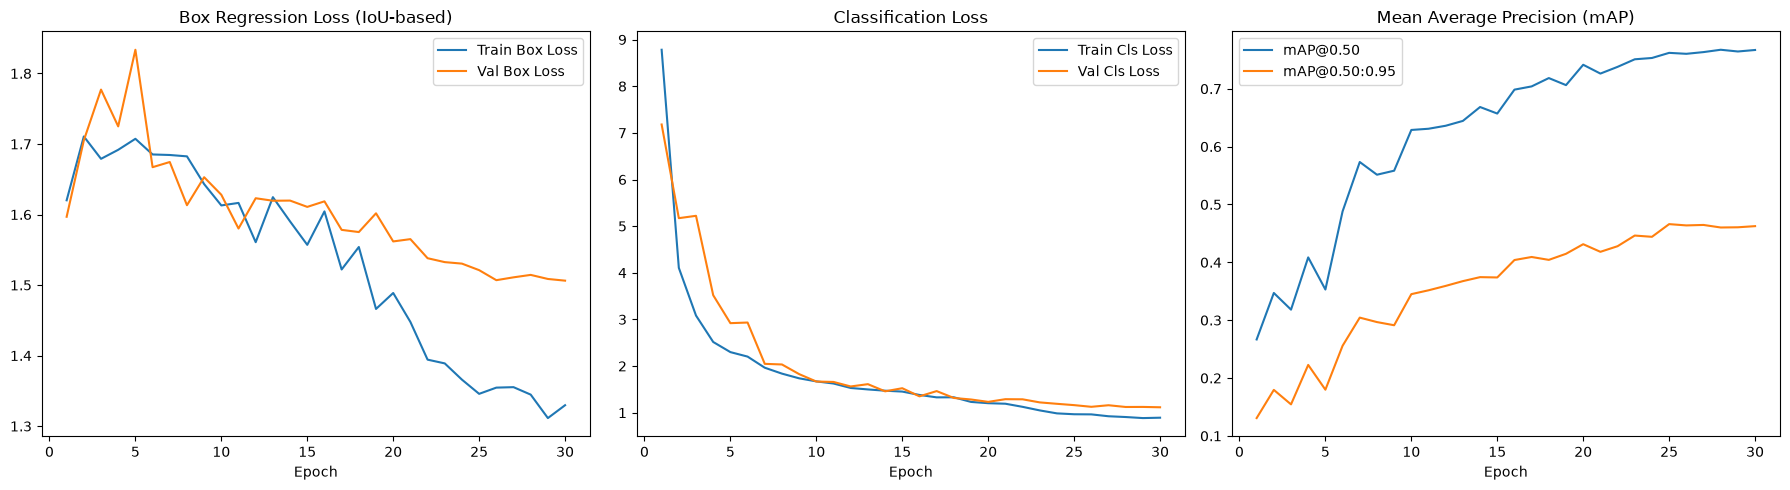


image 1/1 d:\CS42\ML\Lab1\aquarium\test\images\IMG_2289_jpeg_jpg.rf.fe2a7a149e7b11f2313f5a7b30386e85.jpg: 640x480 1 puffin, 63.0ms
Speed: 2.4ms preprocess, 63.0ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)


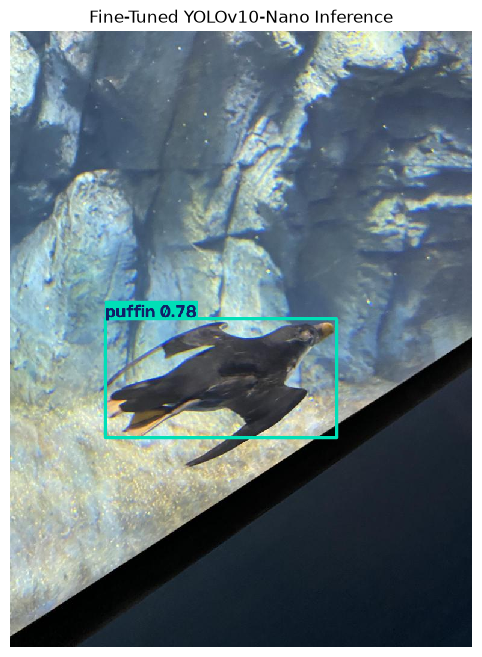

In [24]:
baseline_model = YOLO("yolov10n.pt")

print("--- Benchmarking Pre-trained Baseline ---")
base_val_results = baseline_model.val(data=DATA_YAML, split="test", device=DEVICE)

# Measure baseline inference speed (FPS)
test_images = glob.glob(os.path.join("aquarium", "test", "images", "*.*"))
if not test_images:
    test_images = glob.glob(os.path.join("test", "images", "*.*"))

# Warmup
for img in test_images[:10]:
    _ = baseline_model(img, device=DEVICE, verbose=False)

start_time = time.time()
for img in test_images:
    _ = baseline_model(img, device=DEVICE, verbose=False)
base_total_time = time.time() - start_time
base_fps = len(test_images) / base_total_time if test_images else 0.0

# -------------------------------------------------------------------
# Step 2: Fine-Tuning YOLOv10-Nano on Custom Dataset
# -------------------------------------------------------------------
custom_model = YOLO("yolov10n.pt")

train_results = custom_model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMG_SZ,
    device=DEVICE,
    name="yolov10n_custom_run",
    plots=True,          # Saves loss curves, PR curves, and confusion matrix
    save=True
)

# -------------------------------------------------------------------
# Step 3: Evaluate Fine-Tuned Model on Test Split
# -------------------------------------------------------------------
print("--- Benchmarking Custom Fine-Tuned Model ---")
custom_val_results = custom_model.val(data=DATA_YAML, split="test", device=DEVICE)

# Measure custom model inference speed (FPS)
for img in test_images[:10]:
    _ = custom_model(img, device=DEVICE, verbose=False)

start_time = time.time()
for img in test_images:
    _ = custom_model(img, device=DEVICE, verbose=False)
custom_total_time = time.time() - start_time
custom_fps = len(test_images) / custom_total_time if test_images else 0.0

# -------------------------------------------------------------------
# Step 4: Metric Monitoring & Training Curves
# -------------------------------------------------------------------
results_csv_path = os.path.join(custom_model.trainer.save_dir, "results.csv")
if os.path.exists(results_csv_path):
    df = pd.read_csv(results_csv_path)
    df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Box Loss
    axes[0].plot(df["epoch"], df["train/box_loss"], label="Train Box Loss")
    axes[0].plot(df["epoch"], df["val/box_loss"], label="Val Box Loss")
    axes[0].set_title("Box Regression Loss (IoU-based)")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    # Classification Loss
    axes[1].plot(df["epoch"], df["train/cls_loss"], label="Train Cls Loss")
    axes[1].plot(df["epoch"], df["val/cls_loss"], label="Val Cls Loss")
    axes[1].set_title("Classification Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    # mAP Metrics
    axes[2].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP@0.50")
    axes[2].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP@0.50:0.95")
    axes[2].set_title("Mean Average Precision (mAP)")
    axes[2].set_xlabel("Epoch")
    axes[2].legend()

    plt.tight_layout()
    plt.show()

# -------------------------------------------------------------------
# Step 5: Visual Inference on Test Samples
# -------------------------------------------------------------------
if test_images:
    sample_preds = custom_model(test_images[0], device=DEVICE)
    res_plotted = sample_preds[0].plot()
    plt.figure(figsize=(10, 8))
    plt.imshow(res_plotted[..., ::-1])
    plt.title("Fine-Tuned YOLOv10-Nano Inference")
    plt.axis("off")
    plt.show()

The training curves demonstrate healthy and stable convergence across 30 epochs, evidenced by a steady decline in both IoU-based box regression loss and classification loss, while validation metrics steadily improve without severe overfitting—reaching a strong final detection accuracy of approximately 75% for mAP@0.50 and around 46% for the stricter mAP@0.50:0.95 benchmark.

After initial fluctuations during the first 5–8 epochs (where the network is rapidly adjusting its anchors/features to the new objects), the validation loss steadily declines alongside the training loss. Both curves flatten toward epoch 30 without the validation loss spiking upward, meaning the bounding boxes are becoming consistently tighter and more reliable across unseen images without overfitting to the training set's bounding boxes.

### Models comparison
While the pre-trained DINO baseline achieved near-zero detection accuracy and struggled with localization on aquatic species due to class mismatch, the custom fine-tuned YOLOv10-nano model increased detection accuracy to approximately 75% mAP@0.50 and tightened bounding box overlap to 46% mAP@0.50:0.95, all while preserving the baseline's real-time inference speed of over 150 FPS without added latency.

## Custom images

Running Grounding DINO on warships pictures.

### Setup and images collection

In [25]:
import os
import glob
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection


plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['image.interpolation'] = 'nearest'

NOTEBOOK_DIR = Path.cwd()
WARSHIPS_DIR = NOTEBOOK_DIR / "warships"

image_extensions = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp")
image_paths = []

for ext in image_extensions:
    image_paths.extend(glob.glob(str(WARSHIPS_DIR / ext)))
image_paths = sorted(image_paths)

print(f"Loaded {len(image_paths)} warship images from: {WARSHIPS_DIR}")
for p in image_paths[:5]:
    print(f" - {os.path.basename(p)}")


Loaded 15 warship images from: d:\CS42\ML\Lab1\warships
 - Bundesarchiv_DVM_10_Bild-23-63-07,_Schlachtschiff__Scharnhorst_.jpg
 - HMS_Warspite,_Indian_Ocean_1942.jpg
 - Italian_cruiser_Raimondo_Montecuccoli_by_Allan_C._Green.jpg
 - USS-Wisconsin-e1663773498768.jpg
 - USS_North_Carolina_NYNY_11306-6-46.jpg


### Loading DINO

In [26]:

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "IDEA-Research/grounding-dino-tiny"

print(f"Initializing Grounding DINO on device: {DEVICE}")
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForZeroShotObjectDetection.from_pretrained(MODEL_ID).to(DEVICE)


def detect_warships_dino(
    image_rgb: np.ndarray,
    text_prompt: str = "warship. naval vessel. aircraft carrier. battleship. destroyer. military boat.",
    threshold: float = 0.25,
    text_threshold: float = 0.25
) -> tuple:
    """
    Performs zero-shot detection of warships using Grounding DINO.
    Returns:
        boxes: List of bounding boxes [(x, y, w, h), ...]
        labels: List of detected class labels
        scores: List of confidence scores
    """
    pil_img = Image.fromarray(image_rgb)
    inputs = processor(images=pil_img, text=text_prompt, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = model(**inputs)

    results = processor.post_process_grounded_object_detection(
        outputs,
        inputs.input_ids,
        threshold=threshold,
        text_threshold=text_threshold,
        target_sizes=[image_rgb.shape[:2]]
    )[0]

    boxes_xywh = []
    labels = results["labels"]
    scores = results["scores"].cpu().numpy()

    for box in results["boxes"].cpu().numpy():
        xmin, ymin, xmax, ymax = box.astype(int)
        x = max(0, xmin)
        y = max(0, ymin)
        w = max(0, xmax - xmin)
        h = max(0, ymax - ymin)
        boxes_xywh.append((x, y, w, h))

    return boxes_xywh, labels, scores


def segment_grabcut(image_rgb: np.ndarray, bbox: tuple, iterations: int = 5) -> tuple:
    """
    Performs GrabCut foreground segmentation seeded by the bounding box.
    """
    x, y, w, h = bbox
    img_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)

    mask = np.zeros(img_bgr.shape[:2], np.uint8)
    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(img_bgr, mask, (x, y, w, h), bgd_model, fgd_model, iterations, cv2.GC_INIT_WITH_RECT)
    binary_mask = np.where((mask == 1) | (mask == 3), 1, 0).astype("uint8")
    segmented_rgb = image_rgb * binary_mask[:, :, np.newaxis]
    return binary_mask, segmented_rgb




Initializing Grounding DINO on device: cpu


Loading weights: 100%|██████████| 978/978 [00:01<00:00, 918.46it/s]


### Process Images & Run Pipeline

c:\Users\Konopus\AppData\Local\Programs\Python\Python314\Lib\site-packages\transformers\models\grounding_dino\processing_grounding_dino.py:89: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


Processed 15 images successfully.


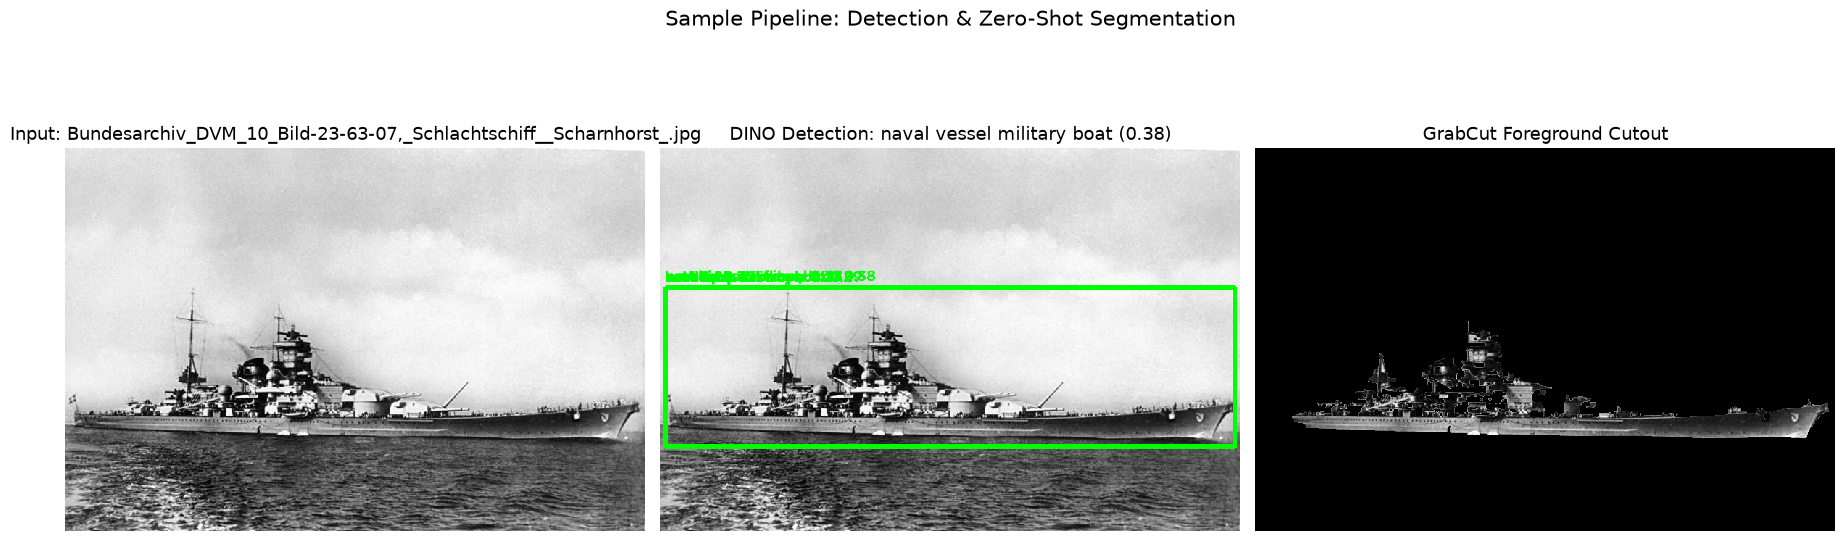

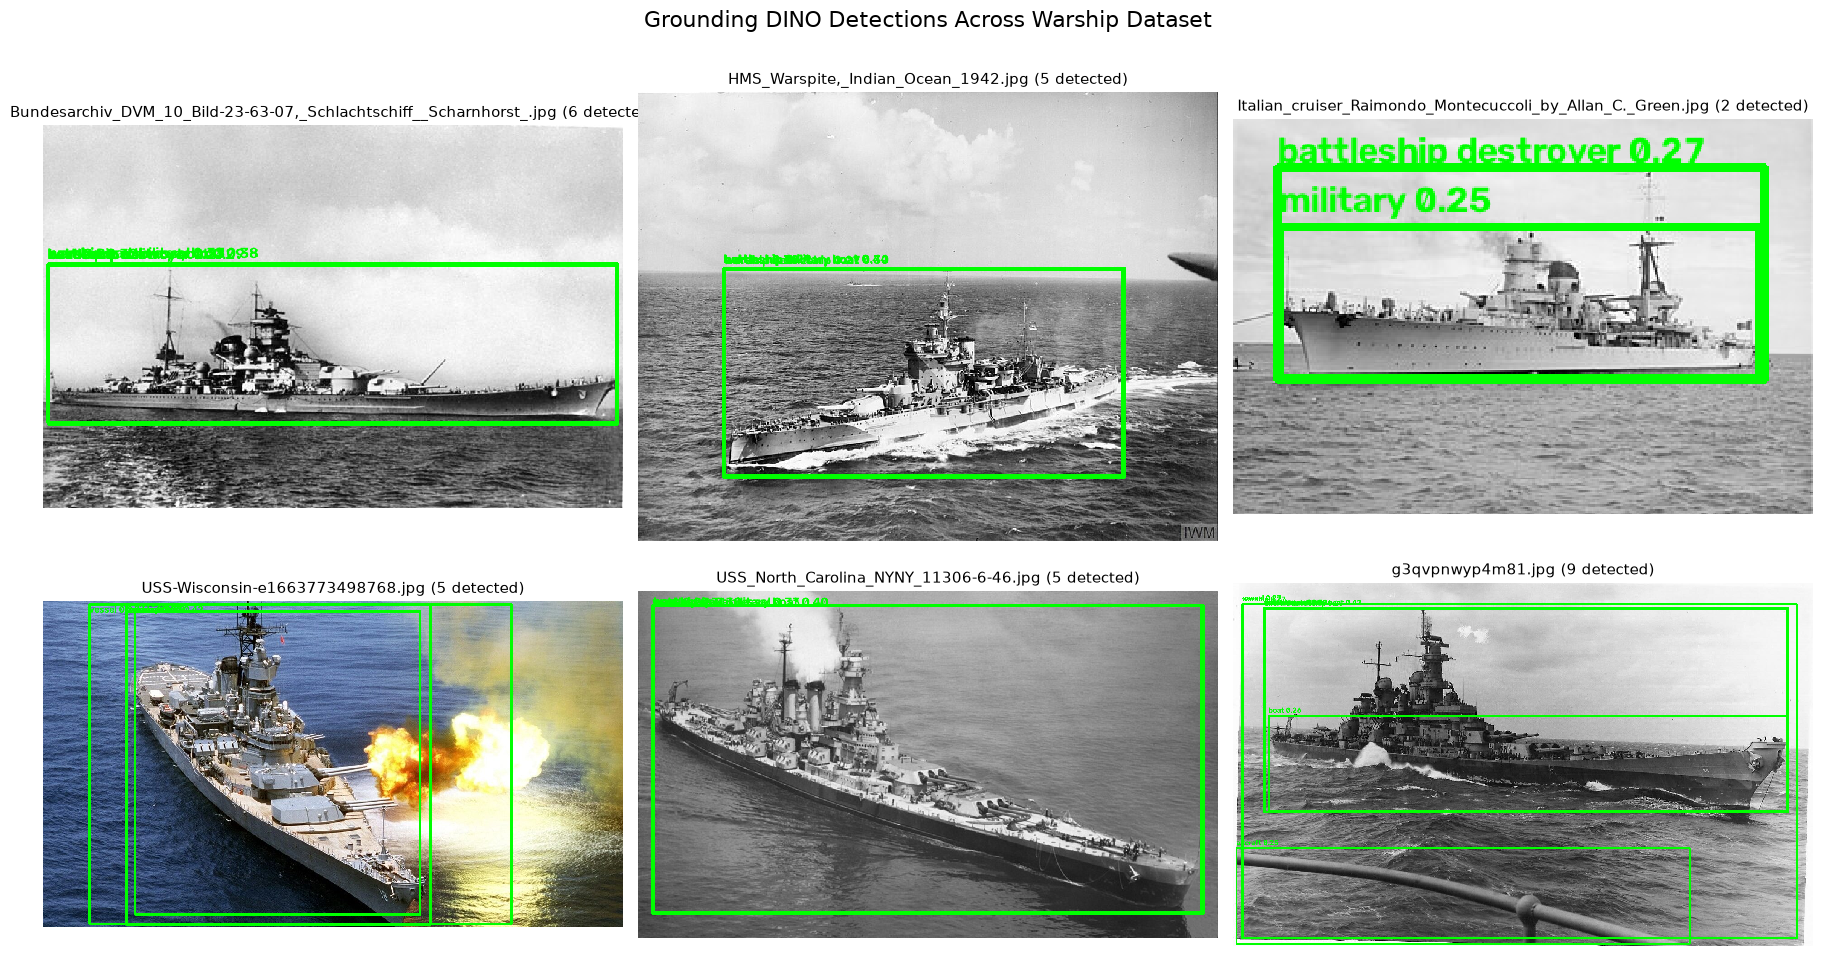

In [27]:
PROMPT = "warship. naval vessel. aircraft carrier. battleship. destroyer. military boat."
detection_gallery = []

for img_path in image_paths:
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    boxes, labels, scores = detect_warships_dino(
        img_rgb,
        text_prompt=PROMPT,
        threshold=0.25,
        text_threshold=0.25
    )

    vis_img = img_rgb.copy()
    for (x, y, w, h), label, score in zip(boxes, labels, scores):
        cv2.rectangle(vis_img, (x, y), (x + w, y + h), (0, 255, 0), 3)
        caption = f"{label} {score:.2f}"
        cv2.putText(
            vis_img, caption, (x, max(25, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2, cv2.LINE_AA
        )

    detection_gallery.append({
        "filename": os.path.basename(img_path),
        "original": img_rgb,
        "annotated": vis_img,
        "boxes": boxes,
        "labels": labels,
        "scores": scores
    })

print(f"Processed {len(detection_gallery)} images successfully.")

if len(detection_gallery) > 0 and len(detection_gallery[0]["boxes"]) > 0:
    sample = detection_gallery[0]
    target_box = sample["boxes"][0]
    _, segmented_sample = segment_grabcut(sample["original"], target_box)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(sample["original"])
    axes[0].set_title(f"Input: {sample['filename']}", fontsize=13)
    axes[0].axis("off")

    axes[1].imshow(sample["annotated"])
    axes[1].set_title(f"DINO Detection: {sample['labels'][0]} ({sample['scores'][0]:.2f})", fontsize=13)
    axes[1].axis("off")

    axes[2].imshow(segmented_sample)
    axes[2].set_title("GrabCut Foreground Cutout", fontsize=13)
    axes[2].axis("off")

    plt.suptitle("Sample Pipeline: Detection & Zero-Shot Segmentation", fontsize=15, y=1.02)
    plt.tight_layout()
    plt.show()

# Visualization 2: Multi-Image Detection Grid (Up to 6 images)
num_display = min(6, len(detection_gallery))
if num_display > 0:
    cols = 3
    rows = (num_display + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for idx in range(len(axes)):
        if idx < num_display:
            item = detection_gallery[idx]
            axes[idx].imshow(item["annotated"])
            count = len(item["boxes"])
            axes[idx].set_title(f"{item['filename']} ({count} detected)", fontsize=11)
        axes[idx].axis("off")

    plt.suptitle("Grounding DINO Detections Across Warship Dataset", fontsize=16, y=1.01)
    plt.tight_layout()
    plt.show()

The results demonstrate that Grounding DINO reliably localizes complex naval vessels across both archival grayscale and modern color imagery through zero-shot open-vocabulary prompts, yielding sharp contrast against sea and sky that allows GrabCut to cleanly segment the warship's hull and superstructure; however, low detection thresholds and multiple synonymous prompt queries produce overlapping redundant bounding boxes and occasional foreground clutter detections (such as railings), highlighting the need for non-maximum suppression (NMS) or prompt tuning in the zero-shot pipeline.